In [ ]:
# setup
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
METRICS = ROOT / "results" / "metrics"
LOGS = ROOT / "results" / "logs"
CM_DIR = ROOT / "results" / "confusion_matrix"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

MODELS = ["mobilenetv2", "efficientnetb0"]
PREPS = ["original", "minmax", "clahe"]
SC = {
    ("mobilenetv2", "original"): "A", ("mobilenetv2", "minmax"): "B", ("mobilenetv2", "clahe"): "C",
    ("efficientnetb0", "original"): "D", ("efficientnetb0", "minmax"): "E", ("efficientnetb0", "clahe"): "F",
}
MODEL_LABEL = {"mobilenetv2": "MobileNetV2", "efficientnetb0": "EfficientNetB0"}
PREP_LABEL = {"original": "Original", "minmax": "Min-Max", "clahe": "CLAHE"}

sns.set_theme(style="whitegrid")
print("ROOT:", ROOT)

ROOT: d:\Kuliah\Semester 7\Pengolahan Citra Digital\UAS\program


In [ ]:
# load hasil evaluasi data testing

rows, per_class = [], []
for f in sorted(METRICS.glob("*_seed*.json")):
    d = json.loads(f.read_text())
    rows.append({k: d[k] for k in ["model", "prep", "seed", "n_test", "accuracy",
                                   "precision_macro", "recall_macro", "f1_macro"]})
    for cls, m in d["per_class"].items():
        if cls in ("accuracy", "macro avg", "weighted avg"):
            continue
        per_class.append({"model": d["model"], "prep": d["prep"], "seed": d["seed"], "class": cls,
                          "precision": m["precision"], "recall": m["recall"],
                          "f1": m["f1-score"], "support": m["support"]})

assert rows, "Belum ada file hasil di results/metrics/. Jalankan train.py dan evaluate.py dulu."

runs = pd.DataFrame(rows)
runs["scenario"] = [SC[(m, p)] for m, p in zip(runs["model"], runs["prep"])]
pcdf = pd.DataFrame(per_class)
pcdf["scenario"] = [SC[(m, p)] for m, p in zip(pcdf["model"], pcdf["prep"])]

done = sorted(runs["scenario"].unique())
missing = sorted(set(SC.values()) - set(done))
print("Skenario tersedia:", done)
print("Skenario belum ada:", missing if missing else "-")
print("Seed yang dipakai:", sorted(int(s) for s in runs["seed"].unique()))
runs.sort_values(["scenario", "seed"]).reset_index(drop=True)

Skenario tersedia: ['A', 'B', 'C', 'D', 'E', 'F']
Skenario belum ada: -
Seed yang dipakai: [42]


,model,prep,seed,n_test,accuracy,precision_macro,recall_macro,f1_macro,scenario
0,mobilenetv2,original,42,981,0.987768,0.988244,0.987973,0.987925,A
1,mobilenetv2,minmax,42,981,0.986748,0.986784,0.987150,0.986762,B
2,mobilenetv2,clahe,42,981,0.988787,0.989157,0.989609,0.989217,C
3,efficientnetb0,original,42,981,0.997961,0.997611,0.997676,0.997605,D
4,efficientnetb0,minmax,42,981,0.997961,0.997611,0.997676,0.997605,E
5,efficientnetb0,clahe,42,981,0.996942,0.997309,0.997206,0.997231,F


In [ ]:
# tabel perbandingan seluruh skenario

metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
g = runs.groupby(["scenario", "model", "prep"])
summary = (g[metrics].mean().add_suffix("_mean")
           .join(g[metrics].std(ddof=1).fillna(0.0).add_suffix("_std"))
           .join(g.size().rename("n_seed"))
           .reset_index().sort_values("scenario").reset_index(drop=True))
summary.to_csv(METRICS / "summary.csv", index=False)

table = pd.DataFrame({
    "Skenario": summary["scenario"],
    "Model": summary["model"].map(MODEL_LABEL),
    "Preprocessing": summary["prep"].map(PREP_LABEL),
    "n seed": summary["n_seed"],
    "Accuracy": [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary["accuracy_mean"], summary["accuracy_std"])],
    "Precision (macro)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary["precision_macro_mean"], summary["precision_macro_std"])],
    "Recall (macro)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary["recall_macro_mean"], summary["recall_macro_std"])],
    "F1 (macro)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary["f1_macro_mean"], summary["f1_macro_std"])],
})
table

,Skenario,Model,Preprocessing,n seed,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,A,MobileNetV2,Original,1,0.9878 ± 0.0000,0.9882 ± 0.0000,0.9880 ± 0.0000,0.9879 ± 0.0000
1,B,MobileNetV2,Min-Max,1,0.9867 ± 0.0000,0.9868 ± 0.0000,0.9872 ± 0.0000,0.9868 ± 0.0000
2,C,MobileNetV2,CLAHE,1,0.9888 ± 0.0000,0.9892 ± 0.0000,0.9896 ± 0.0000,0.9892 ± 0.0000
3,D,EfficientNetB0,Original,1,0.9980 ± 0.0000,0.9976 ± 0.0000,0.9977 ± 0.0000,0.9976 ± 0.0000
4,E,EfficientNetB0,Min-Max,1,0.9980 ± 0.0000,0.9976 ± 0.0000,0.9977 ± 0.0000,0.9976 ± 0.0000
5,F,EfficientNetB0,CLAHE,1,0.9969 ± 0.0000,0.9973 ± 0.0000,0.9972 ± 0.0000,0.9972 ± 0.0000


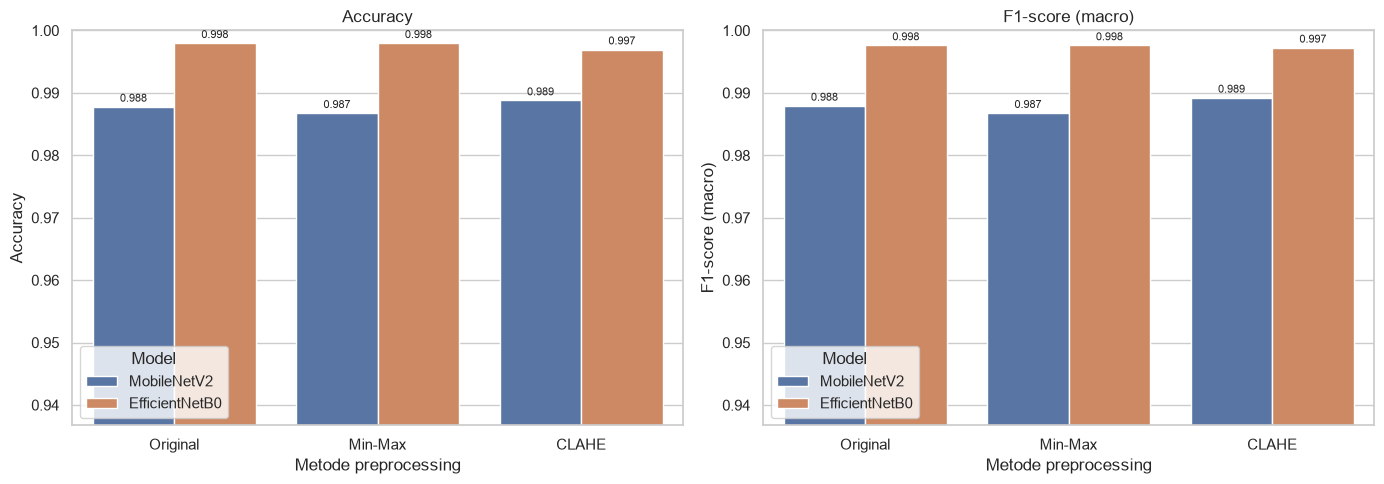

In [ ]:
# grafik perbandingan metrik evaluasi

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ["accuracy", "f1_macro"], ["Accuracy", "F1-score (macro)"]):
    plot_df = runs.assign(Model=runs["model"].map(MODEL_LABEL), Prep=runs["prep"].map(PREP_LABEL))
    sns.barplot(data=plot_df, x="Prep", y=metric, hue="Model", ax=ax, errorbar="sd",
                order=[PREP_LABEL[p] for p in PREPS], hue_order=[MODEL_LABEL[m] for m in MODELS])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
    lo = max(0, runs[metric].min() - 0.05)
    ax.set_ylim(lo, min(1.0, runs[metric].max() + 0.03))
    ax.set_title(title)
    ax.set_xlabel("Metode preprocessing")
    ax.set_ylabel(title)
plt.tight_layout()
plt.savefig(FIG / "perbandingan_metrik.png", dpi=200)
plt.show()

In [ ]:
# tabel selisih metrik evaluasi terhadap baseline (original)

def delta_table(metric):
    piv = summary.pivot(index="model", columns="prep", values=f"{metric}_mean").reindex(columns=PREPS)
    out = (piv[["minmax", "clahe"]].sub(piv["original"], axis=0) * 100).round(2)
    out.index = out.index.map(MODEL_LABEL)
    out.columns = [f"{PREP_LABEL[c]} - Original (poin %)" for c in out.columns]
    return out

print("Selisih Accuracy:")
display(delta_table("accuracy"))
print("Selisih F1 (macro):")
display(delta_table("f1_macro"))

Selisih Accuracy:


,Min-Max - Original (poin %),CLAHE - Original (poin %)
model,,
EfficientNetB0,0.0,-0.1
MobileNetV2,-0.1,0.1


Selisih F1 (macro):


,Min-Max - Original (poin %),CLAHE - Original (poin %)
model,,
EfficientNetB0,0.00,-0.04
MobileNetV2,-0.12,0.13


Simpangan baku akurasi terbesar antar-seed: 0.00 poin %
Hanya 1 seed: tidak ada estimasi noise, jangan menyimpulkan dari selisih kecil.


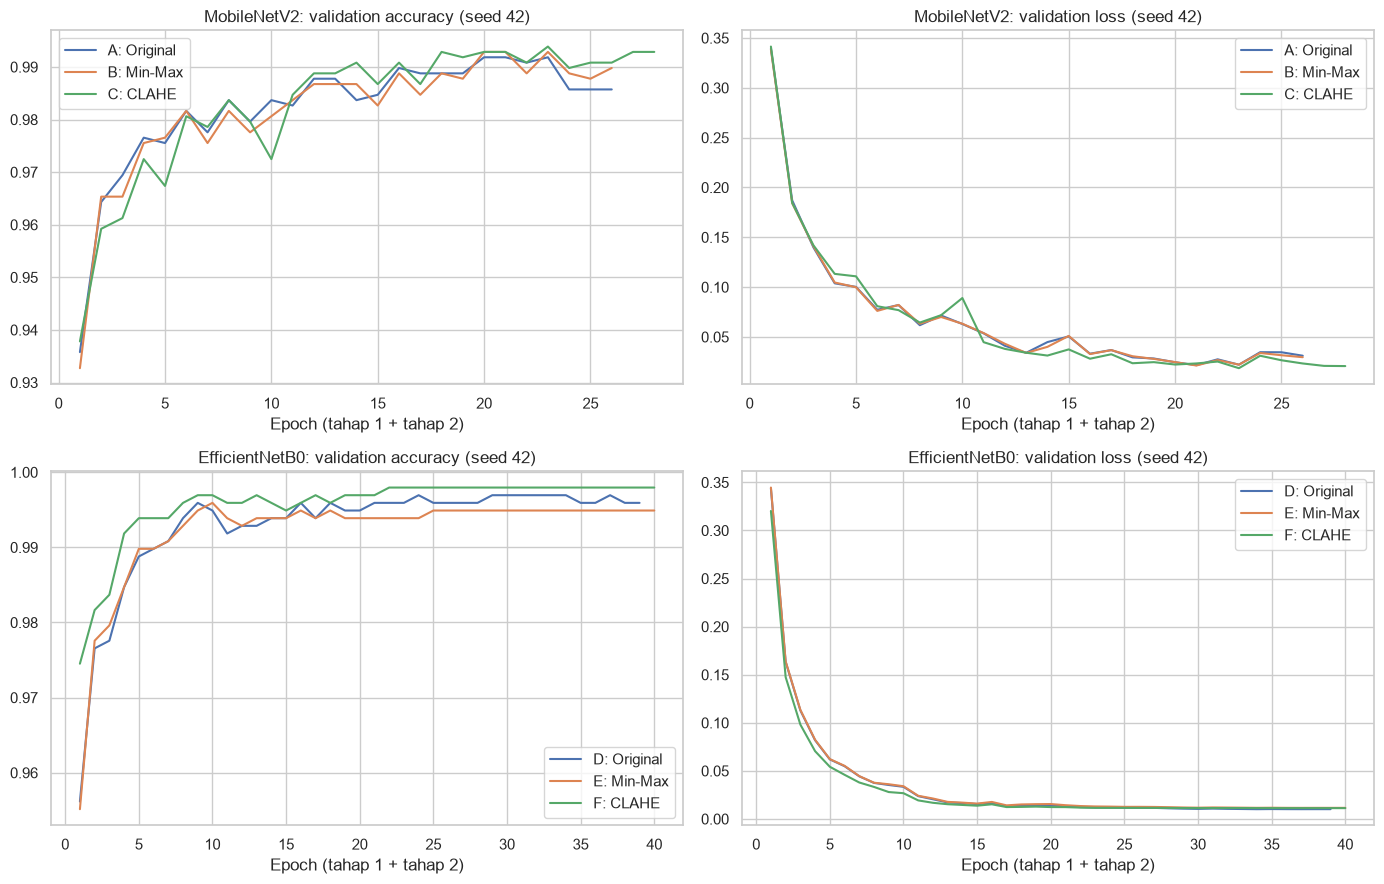

In [ ]:
# kurva training data validasi

SEED_PLOT = int(runs["seed"].min()) 

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for r, model in enumerate(MODELS):
    for prep in PREPS:
        f = LOGS / f"{model}_{prep}_seed{SEED_PLOT}_history.csv"
        if not f.exists():
            continue
        h = pd.read_csv(f)
        label = f"{SC[(model, prep)]}: {PREP_LABEL[prep]}"
        axes[r, 0].plot(h["epoch"] + 1, h["val_accuracy"], label=label)
        axes[r, 1].plot(h["epoch"] + 1, h["val_loss"], label=label)
    axes[r, 0].set_title(f"{MODEL_LABEL[model]}: validation accuracy (seed {SEED_PLOT})")
    axes[r, 1].set_title(f"{MODEL_LABEL[model]}: validation loss (seed {SEED_PLOT})")
    for ax in axes[r]:
        ax.set_xlabel("Epoch (tahap 1 + tahap 2)")
        ax.legend()
plt.tight_layout()
plt.savefig(FIG / "kurva_training.png", dpi=200)
plt.show()

In [ ]:
# waktu dan jumlah epoch training

meta = []
for f in sorted(LOGS.glob("*_train.json")):
    d = json.loads(f.read_text())
    d["scenario"] = SC[(d["model"], d["prep"])]
    meta.append(d)

if meta:
    mdf = pd.DataFrame(meta)
    out = (mdf.groupby(["scenario", "model", "prep"])
              [["epochs_head", "epochs_finetune", "train_seconds"]].mean().round(1).reset_index())
    out["train_menit"] = (out["train_seconds"] / 60).round(1)
    out["model"] = out["model"].map(MODEL_LABEL)
    out["prep"] = out["prep"].map(PREP_LABEL)
    display(out.drop(columns="train_seconds"))
else:
    print("Belum ada file log training.")

,scenario,model,prep,epochs_head,epochs_finetune,train_menit
0,A,MobileNetV2,Original,10.0,16.0,43.6
1,B,MobileNetV2,Min-Max,10.0,16.0,40.9
2,C,MobileNetV2,CLAHE,10.0,18.0,49.4
3,D,EfficientNetB0,Original,10.0,29.0,85.4
4,E,EfficientNetB0,Min-Max,10.0,30.0,90.8
5,F,EfficientNetB0,CLAHE,10.0,30.0,89.9


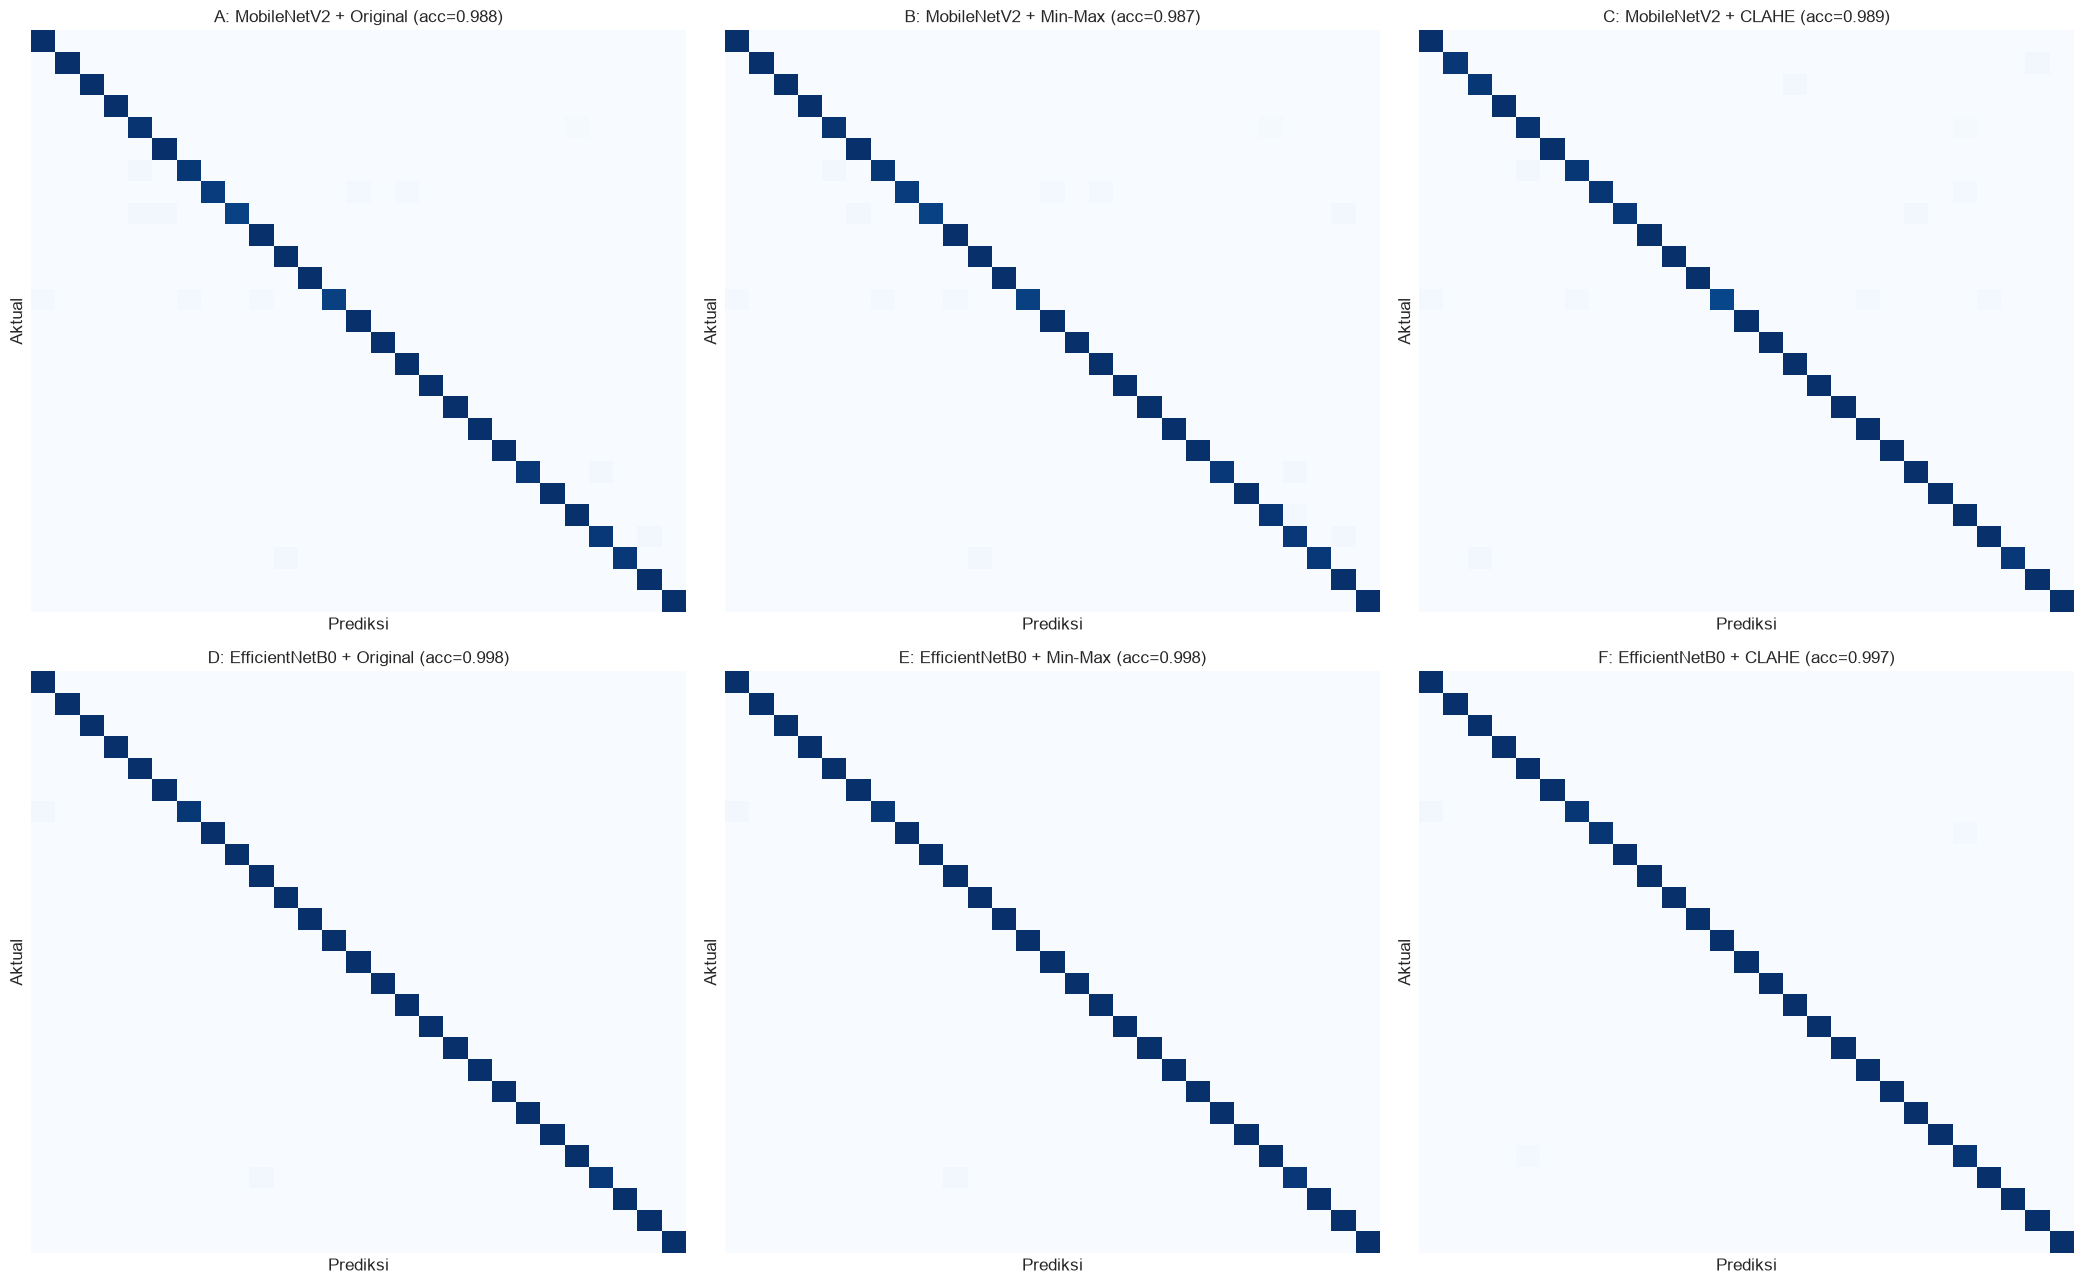

Versi lengkap dengan label dan angka per skenario ada di results/confusion_matrix/*.png


In [ ]:
# visualisasi confusion matrix

def load_cm(model, prep):
    files = sorted(CM_DIR.glob(f"{model}_{prep}_seed*.csv"))
    if not files:
        return None
    total = None
    for f in files:
        cm = pd.read_csv(f, index_col=0)
        total = cm if total is None else total + cm
    return total

cms = {SC[(m, p)]: load_cm(m, p) for m in MODELS for p in PREPS}
cms = {k: v for k, v in cms.items() if v is not None}

fig, axes = plt.subplots(2, 3, figsize=(21, 13))
for ax in axes.ravel():
    ax.axis("off")
for (model, prep), ax in zip([(m, p) for m in MODELS for p in PREPS], axes.ravel()):
    key = SC[(model, prep)]
    if key not in cms:
        continue
    cm = cms[key]
    norm = cm.div(cm.sum(axis=1).replace(0, 1), axis=0)
    ax.axis("on")
    sns.heatmap(norm, cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=False, yticklabels=False)
    acc = np.trace(cm.values) / cm.values.sum()
    ax.set_title(f"{key}: {MODEL_LABEL[model]} + {PREP_LABEL[prep]} (acc={acc:.3f})")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.savefig(FIG / "confusion_matrix_semua.png", dpi=150)
plt.show()
print("Versi lengkap dengan label dan angka per skenario ada di results/confusion_matrix/*.png")

In [ ]:
# kelas yang paling sering tertukar (confused) per skenario

def top_confused(cm, n=5):
    arr = cm.to_numpy().copy()
    np.fill_diagonal(arr, 0)
    s = pd.DataFrame(arr, index=cm.index, columns=cm.columns).stack().sort_values(ascending=False).head(n)
    return [(a, p, int(c)) for (a, p), c in s.items() if c > 0]

rows = []
for key in sorted(cms):
    for a, p, c in top_confused(cms[key]):
        rows.append({"Skenario": key, "Aktual": a, "Diprediksi": p, "Jumlah": c})
pd.DataFrame(rows)

,Skenario,Aktual,Diprediksi,Jumlah
0,A,Rose,crown flower,1
1,A,chitrak,Nityakalyani,1
2,A,Rose,indian mallow,1
3,A,Yellow_Daisy,Jatropha,1
4,A,Jatropha,thechi,1
5,B,Rose,crown flower,1
6,B,chitrak,adathoda,1
7,B,Rose,indian mallow,1
8,B,Yellow_Daisy,tridax procumbens,1
9,B,Jatropha,thechi,1


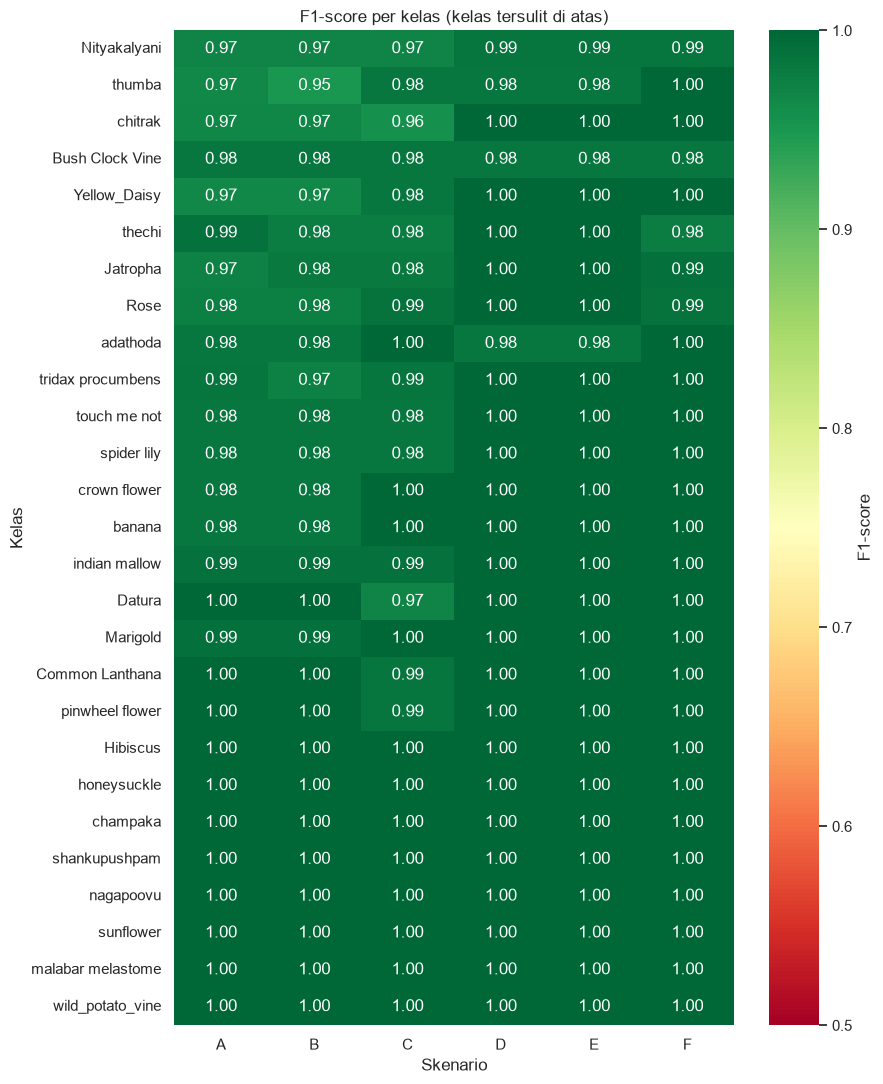

10 kelas tersulit (rata-rata F1 semua skenario):


,rata-rata F1
class,
Nityakalyani,0.978
thumba,0.978
chitrak,0.982
Bush Clock Vine,0.984
Yellow_Daisy,0.986
thechi,0.987
Jatropha,0.988
Rose,0.988
adathoda,0.989


In [ ]:
# f1-score per kelas

pc = pcdf.groupby(["class", "scenario"])["f1"].mean().unstack()
pc = pc.reindex(columns=sorted(pc.columns))
order = pc.mean(axis=1).sort_values().index
pc = pc.loc[order]

plt.figure(figsize=(9, 11))
sns.heatmap(pc, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1.0,
            cbar_kws={"label": "F1-score"})
plt.title("F1-score per kelas (kelas tersulit di atas)")
plt.xlabel("Skenario")
plt.ylabel("Kelas")
plt.tight_layout()
plt.savefig(FIG / "f1_per_kelas.png", dpi=200)
plt.show()

print("10 kelas tersulit (rata-rata F1 semua skenario):")
display(pc.mean(axis=1).head(10).round(3).rename("rata-rata F1").to_frame())